In [1]:
#!/usr/bin/env python3

import os, sys,glob
sys.path.append('../')
import numpy as np
from matplotlib import pyplot as plt
import matplotlib as mpl
from collections import namedtuple
import pandas as pd
from helper import getModelDict
from triggers_helper import in_N,in_Np1,in_ms,in_hcal
try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass
delphesDir = os.path.abspath("../../DelphesLLP")
os.environ['ROOT_INCLUDE_PATH'] = os.path.join(delphesDir,"external")

import ROOT


ROOT.gSystem.Load(os.path.join(delphesDir,"libDelphes.so"))

ROOT.gInterpreter.Declare('#include "classes/SortableObject.h"')
ROOT.gInterpreter.Declare('#include "classes/DelphesClasses.h"')
ROOT.gInterpreter.Declare('#include "external/ExRootAnalysis/ExRootTreeReader.h"')



Welcome to JupyROOT 6.30/06


True

In [2]:
def get_labels(df_selected,all_df=[],full_label=False):

    labels = {'mS' : lambda x: r'$m_S$ =' + f' {x:1.2f} [GeV]',
          'm1' : lambda x: r'$m_{\chi_1}$ =' + f' {x:1.2f} [GeV]',
          'dm' : lambda x: r'$\Delta m$ =' + f' {x:1.2f} [GeV]',
          'tau' : lambda x: r'$c \tau$ =' + f' {x*3e8:1.0f} [m]',
        #   'm0' : lambda x: r'$m_{\chi_0}$ =' + f' {x:1.2f} [GeV]',
        #   'm2' : lambda x: r'$m_{\chi_2}$ =' + f' {x:1.2f} [GeV]'          
         }

    model_label = [labels[k](float(df_selected[k].values[0])) for k in labels if k in df_selected.columns]
    if full_label:
        return ', '.join(model_label)
    all_labels = []
    for df in all_df:
        all_labels.append([labels[k](float(df[k].values[0])) for k in labels if k in df.columns])
    labelsDict = {}
    for labelList in all_labels:
        for label in labelList:
            labelsDict.setdefault(label,0)
            labelsDict[label] += 1
    common_labels = [l for l,c in labelsDict.items() if c == len(all_labels)]
    short_label = [l for l in model_label if l not in common_labels]
    short_label = ', '.join(short_label)
    common_label = ', '.join(common_labels)
    return short_label,common_label


def closestDF(dfList, point, relative=True):
    """Return the DataFrame with the parameters closest to point 
    (dict column -> value)."""
    min_dist = float('inf')
    closest_df = None
    for df in dfList:
        row = df.iloc[0]
        cols = list(point.keys())
        target = pd.Series(point)
        diff = row[cols] - target
        if relative:
            diff = diff / target.abs().where(target != 0, 1.0)   # relative difference (absolute if target is 0)
        dist = sum(diff**2)
        if dist < min_dist:
            min_dist = dist
            closest_df = df
    return closest_df   # double brackets keep it a DataFrame


## Read events

In [40]:
processFolders = '../../processFolders/test'


runs = ['run_01']

files = []
for f in runs:
    runFolder = os.path.join(processFolders, 'Events', f)
    rootFile = list(glob.glob(os.path.join(runFolder, '*.root')))[0]
    files.append(rootFile)

c_light = 2.99792458e8

### Get Event information

In [62]:
dfList = []
decayVertex = namedtuple('decayVertex',['x','y','z','t','beta','l','rho'])
for file in files:
    if not os.path.isfile(file):
        print(f"File {file} not found, skipping")
        continue
    f = ROOT.TFile(file,'read')
    tree = f.Get("Delphes")
    nevts = tree.GetEntries()
    rDecays = []
    metList = []
    met_invList = []
    modelData = getModelDict(file,verbose=False)
    modelData['dm'] = modelData['m1'] - modelData['m0']
    modelData['ctau'] = modelData['tau']*c_light
    for ievt in range(nevts):
        tree.GetEntry(ievt)

        llps = list(tree.llpParticles)
        for illp,llp in enumerate(llps):
            daughter = None
            for d in tree.llpDirectDaughters:
                if d.M1 == illp:
                    daughter = d
                    break
            if daughter is None:
                raise ValueError(f"Event {ievt} has no daughter for llp {illp}")
            llp.Xdecay = d.X*1e-3
            llp.Ydecay = d.Y*1e-3
            llp.Zdecay = d.Z*1e-3
            llp.Tdecay = d.T
            l = float(np.linalg.norm([llp.Xdecay,llp.Ydecay,llp.Zdecay]))
            treadout = llp.Tdecay-l/c_light
            llp.Treadout = treadout*1e9       
            p = np.array([llp.Px,llp.Py,llp.Pz,llp.E])
            beta = np.linalg.norm(p[:3])/p[3]
            llp.beta = beta

        llpDec = {}
        for illp,llp in enumerate(llps):
            beta = llp.beta
            decayVtx = decayVertex(llp.Xdecay,llp.Ydecay,llp.Zdecay,llp.Treadout,beta,
                                   float(np.linalg.norm([llp.Xdecay,llp.Ydecay,llp.Zdecay])),
                                   float(np.linalg.norm([llp.Xdecay,llp.Ydecay,llp.Zdecay])))
            llpDec[illp] = decayVtx
        decs = sorted(llpDec.values(), key = lambda d : d[3])
        if len(decs) != 1:
            raise ValueError(f"Event {ievt} has {len(decs)} decays, expected 1")


        # Get invisible particles (in N)
        invisibles = []
        # Add LLP if it does not decay in N
        for illp,llpDec in llpDec.items():
            if not in_N(llpDec.t):
                invisibles.append(llps[illp])
            else:
                for d in tree.llpDirectDaughters:
                    if d.M1 != illp:
                        continue
                    if abs(d.PID) == 4000022:
                        invisibles.append(d)

        for d in tree.llp2DirectDaughters:
            if abs(d.PID) == 4000022:
                invisibles.append(d)
        
        # Compute real MET
        met_inv = np.array([0.,0.])
        for inv in invisibles:
            met_inv[0] -= inv.Px
            met_inv[1] -= inv.Py
        met_inv = np.linalg.norm(met_inv)
        met = tree.L1METOnTime.At(0).MET
        # if abs(met_inv-met)/met > 0.5 and met > 50.0:
        #     print(f"Event {ievt} has MET {met} and MET invisible {met_inv}, difference > 50%")
        #     print('Invisible particles:',[p.PID for p in invisibles])
        #     for llp in llps:
        #         print(f"LLP {llp.PID} at ({llp.Xdecay:.2f},{llp.Ydecay:.2f},{llp.Zdecay:.2f}) m, beta={llp.beta:.3f}, treadout = {llp.Treadout:.2f} ns")
        #     for bsm in invisibles:
        #         print(f"LSP {bsm.PID} at ({bsm.X*1e-3:.2f},{bsm.Y*1e-3:.2f},{bsm.Z*1e-3:.2f}) m, t_readout={bsm.T:.2f} ns")

        #     chi1 = [p for p in tree.llpParticles if abs(p.PID) == 4000023][0]
        #     chi2 = [p for p in tree.llp2Particles if abs(p.PID) == 4000024][0]
        #     chi1Daughters = [p for p in tree.llpDirectDaughters]
        #     chi2Daughters = [p for p in tree.llp2DirectDaughters]
        #     chi1FinalDaughters = [p for p in tree.llpFinalDaughters]
        #     chi2FinalDaughters = [p for p in tree.llp2FinalDaughters]


        #     raise ValueError(f"Event {ievt} has MET {met} and MET invisible {met_inv}, difference > 50%")


        rDecays.append(decs[0])
        metList.append(met)
        met_invList.append(met_inv)
    f.Close()
    df = pd.DataFrame(rDecays, columns=decayVertex._fields)
    df['met_inv'] = met_invList
    df['met'] = metList
    for k,v in modelData.items():
        df[k] = v
    dfList.append(df)


In [42]:
print('chi1:')
print(chi1.PID,chi1.Px,chi1.Py,chi1.Treadout,'PT=',np.linalg.norm([chi2.Px,chi2.Py]))
pTd = np.zeros(2)
for d in chi1Daughters:
    print(' ',d.PID,d.Px,d.Py,d.T)
    pTd += np.array([d.Px,d.Py])
print('chi1 daughters PT =',np.linalg.norm(pTd))

print('\nchi2:')
print(chi2.PID,chi2.Px,chi2.Py,chi2.T,'PT=',np.linalg.norm([chi2.Px,chi2.Py]))
pTd = np.zeros(2)
for d in chi2Daughters:
    print(' ',d.PID,d.Px,d.Py,d.T)    
    pTd += np.array([d.Px,d.Py])
print('chi2 daughters PT =',np.linalg.norm(pTd))

print('\nISR(chi1+chi2):')
print('chi1+chi2 Px,Py =',chi1.Px+chi2.Px,chi1.Py+chi2.Py,'PT=',np.linalg.norm([chi1.Px+chi2.Px,chi1.Py+chi2.Py]))

chi1:
4000023 233.03860473632812 46.638710021972656 36.669525282857435 PT= 185.73198416938303
  5 1.5107536315917969 3.9307217597961426 3.995316149030259e-07
  -5 12.277883529663086 4.669469833374023 3.995316149030259e-07
  4000022 219.24996948242188 38.038516998291016 3.995316149030259e-07
chi1 daughters PT = 237.65975958395973

chi2:
-4000024 185.7317352294922 -0.30409231781959534 6.85631060201856e-25 PT= 185.73198416938303
  5 14.020393371582031 4.737737655639648 2.8354380475492658e-12
  -5 6.162992477416992 -7.461130142211914 2.8354380475492658e-12
  -4000022 165.54835510253906 2.419300079345703 2.8354380475492658e-12
chi2 daughters PT = 185.73198989156762

ISR(chi1+chi2):
chi1+chi2 Px,Py = 418.7703399658203 46.33461770415306 PT= 421.325876766285


In [43]:
pTmet = np.array([0.,0.])
pTmet += -np.array([chi1.Px,chi1.Py]) - np.array([chi2.Px,chi2.Py]) # ISR pT
for d in chi2Daughters:
    if abs(d.PID) == 4000022:
        continue
    pTmet += np.array([d.Px,d.Py]) # visible chi2 daughters

print('MET=',np.linalg.norm(pTmet))

MET= 401.5946318814512


In [44]:
pTinv = np.array([0.,0.])
pTinv += np.array([chi1.Px,chi1.Py])
for d in chi2Daughters:
    if abs(d.PID) != 4000022:
        continue
    pTinv += np.array([d.Px,d.Py]) # visible chi2 daughters

print('inv=',np.linalg.norm(pTinv))

inv= 401.59463754972097


In [45]:
pTjets = np.array([0.,0.])
for j in tree.HLTJetOnTime:
    pTjets += np.array([j.PT*np.cos(j.Phi),j.PT*np.sin(j.Phi)])
    print('HLTJetOnTime',j.PT,j.Eta)
print('HLTJetOnTime PT =',np.linalg.norm(pTjets))

HLTJetOnTime 413.00323486328125 1.8134021759033203
HLTJetOnTime 53.387813568115234 -0.8620492815971375
HLTJetOnTime 40.89590072631836 0.7658858895301819
HLTJetOnTime PT = 429.3883557769865


In [46]:
pTisr = -np.array([chi1.Px,chi1.Py]) - np.array([chi2.Px,chi2.Py]) 
print('PT ISR=',np.linalg.norm(pTisr))

PT ISR= 421.325876766285


In [47]:
for d in chi2Daughters:
    if abs(d.PID) == 4000022:
        continue
    print('Visible chi2 daughter:', d.Px, d.Py, 'PT=',np.linalg.norm([d.Px,d.Py]))

Visible chi2 daughter: 14.020393371582031 4.737737655639648 PT= 14.799242831562946
Visible chi2 daughter: 6.162992477416992 -7.461130142211914 PT= 9.677341539685452


In [48]:
towers = list(tree.l1calOnTimeTowers)
pTtowers = np.array([0.,0.])
for i,t in enumerate(towers):
    pTtowers += np.array([t.ET*np.cos(t.Phi),t.ET*np.sin(t.Phi)])
    # print(i,'partial PT=',np.linalg.norm(pTtowers))
print('PT towers=',np.linalg.norm(pTtowers))

PT towers= 203.13175337698192


In [61]:
t= towers[59]
print(len(t.Particles),'particles in tower with ET=',t.ET,'Phi=',t.Phi,t.Eta)
for e in t.Edges:
    print(e)
for p in t.Particles:
    phi = np.arctan2(p.Py,p.Px)
    eta = 0.5*np.log((np.linalg.norm([p.Px,p.Py,p.Pz])+p.Pz)/(np.linalg.norm([p.Px,p.Py,p.Pz])-p.Pz))
    pT = np.linalg.norm([p.Px,p.Py])
    print(' ',p.PID,phi,eta,pT)

1 particles in tower with ET= 0.30314913392066956 Phi= -2.1500000953674316 -2.799999952316284
-2.9000000953674316
-2.700000047683716
-2.200000047683716
-2.0999999046325684
  4000022 0.1717838797441124 -1.434805959873152 222.5252297908536


In [49]:
for d in chi1FinalDaughters:
    itower = None
    for i,t in enumerate(towers):
        if d in t.Particles:
            if itower is not None:
                print(f"Warning: particle {d.PID} found in multiple towers ({itower} and {i})")
            itower = i
    if itower is not None:
        print(f"Final daughter {d.PID} found in tower {itower} with ET={towers[itower].ET:.2f} and Phi={towers[itower].Phi:.2f}")



Final daughter 4000022 found in tower 335 with ET=0.58 and Phi=-0.05
Final daughter 22 found in tower 538 with ET=1.28 and Phi=2.75
Final daughter 211 found in tower 532 with ET=1.58 and Phi=1.95
Final daughter 211 found in tower 537 with ET=1.61 and Phi=2.65
Final daughter -211 found in tower 491 with ET=1.17 and Phi=-2.55
Final daughter 13 found in tower 318 with ET=2.75 and Phi=1.05
Final daughter -14 found in tower 521 with ET=1.02 and Phi=2.15
Final daughter -11 found in tower 520 with ET=1.63 and Phi=2.05
Final daughter 12 found in tower 480 with ET=0.39 and Phi=-0.15
Final daughter 321 found in tower 310 with ET=0.15 and Phi=-2.25
Final daughter -211 found in tower 377 with ET=3.75 and Phi=-2.95
Final daughter 211 found in tower 525 with ET=0.58 and Phi=-2.05
Final daughter -211 found in tower 418 with ET=0.06 and Phi=0.35
Final daughter 22 found in tower 382 with ET=0.17 and Phi=-2.35
Final daughter 22 found in tower 248 with ET=0.33 and Phi=-0.15
Final daughter 22 found in tow

In [50]:
for d in chi2FinalDaughters:
    itower = None
    for i,t in enumerate(towers):
        if d in t.Particles:
            if itower is not None:
                print(f"Warning: particle {d.PID} found in multiple towers ({itower} and {i})")
            itower = i
    if itower is None:
        print(f"Final daughter {d.PID} not found in tower")



In [26]:
for df in dfList:
    print(f"{get_labels(df, full_label=True)}: {len(df)} events")

$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 246.30 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m]: 7627 events


### Split LLPs decaying in N-1 and N and in MS and HCAL

In [63]:
for df in dfList:
    df['ontime'] = in_N(df['t'])
    df['delayed'] = in_Np1(df['t'])
    df['in MS'] = in_ms(df['z'],df['rho'])
    df['in HCAL'] = in_hcal(df['z'],df['rho'])
    label = get_labels(df, full_label=True)
    print(f'\n{label} :\n decays in N = {sum(df["ontime"])/len(df):1.4f}, decays in N+1 = {sum(df["delayed"])/len(df):1.4f}')


$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 246.30 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in N = 0.3669, decays in N+1 = 0.2022


### Count decays in N+1 and MS

In [64]:
for df in dfList:
    label = get_labels(df, full_label=True)
    nMS_delayed = len(df[df['in MS'] & df['delayed']])/sum(df["delayed"])
    print(f'{label} :\n decays in MS = {nMS_delayed:1.4f}\n')

print("\nImposing MET > 200")
for df in dfList:
    label = get_labels(df, full_label=True)
    nMS_delayed = len(df[df['in MS'] & df['delayed'] & (df['met'] > 200)])/sum(df["delayed"])
    print(f'{label} :\n decays in MS = {nMS_delayed:1.4f}\n')
    


$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 246.30 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.1258


Imposing MET > 200
$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 246.30 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.0058



In [65]:
selectPoints = [{'mS' : 500.0, 'dm' : 15.0, 'm1' : 246.0, 'ctau' : 20.0}]
df_filtered = [closestDF(dfList, point) for point in selectPoints]
common_label = get_labels(df_filtered[0], all_df=df_filtered, full_label=False)[1]

### MET Distribution

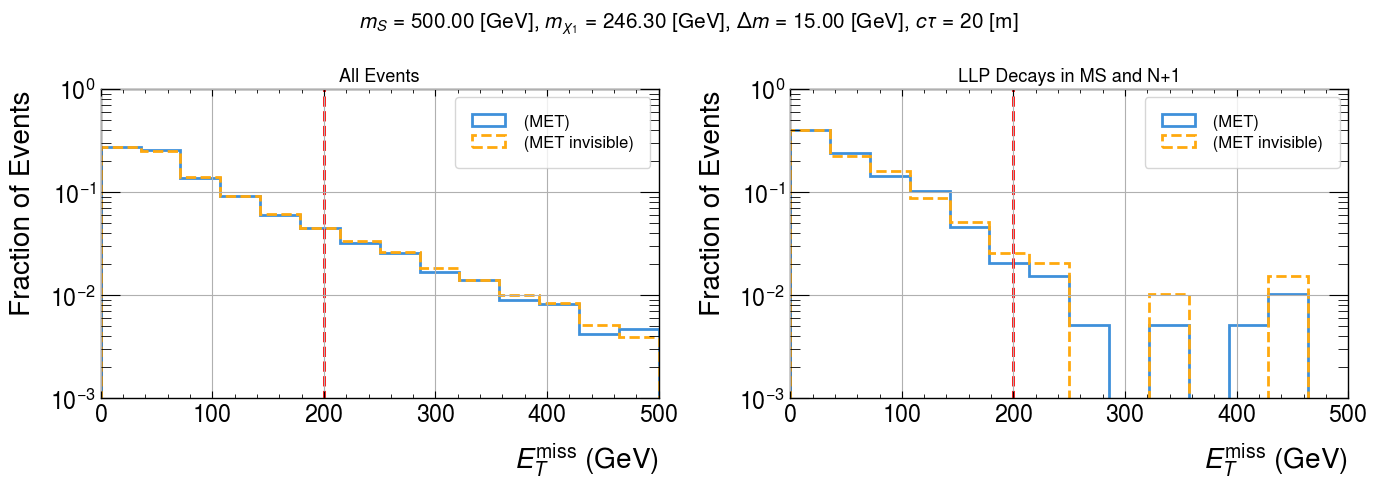

In [66]:

nrows, ncols = 1,2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 5*nrows))
axes = axes.flatten() if nrows*ncols > 1 else [axes]
plt.suptitle(common_label,fontsize=15)
for ax,inMS in zip(axes,[False,True]):
    if inMS:
        ax.set_title(fr'LLP Decays in MS and N+1',fontsize=13)
    else:
        ax.set_title(fr'All Events',fontsize=13)
    for df0 in df_filtered:
        if inMS:
            df = df0[df0['in MS'] & df0['delayed']]
        else:
            df = df0
        short_label = get_labels(df, all_df=df_filtered, full_label=False)[0]
        ax.hist(df['met'],bins=np.linspace(0.,500.0,15),
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=f'{short_label} (MET)',linewidth=2)
        ax.hist(df['met_inv'],bins=np.linspace(0.,500.0,15),
                     histtype='step',linestyle='dashed',
                     weights=[1.0/len(df)]*len(df),
                     label=f'{short_label} (MET invisible)',linewidth=2)
        ax.set_yscale('log')
        ax.set_xlabel(r'$E_T^{\rm miss}$ (GeV)')
        ax.set_ylabel('Fraction of Events')
        ax.legend(loc='upper right',framealpha=0.8,frameon=True,fontsize=12)
        ax.set_ylim(1e-3,1.0)
        ax.grid()
        ax.vlines(x=200.,ymin=0.,ymax=1.0,color='red',linestyles='dashed')
plt.tight_layout()
plt.show()

In [ ]:
# 